In [1]:
import importlib, subprocess, sys, os, time, random, warnings


def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])


try:                                   # install only what is missing
    import torch, torchvision
except ImportError:
    _pip("torch", "torchvision")
    import torch, torchvision
try:
    import opacus
except ImportError:
    _pip("opacus")
    import opacus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator

warnings.filterwarnings("ignore")

# ---- constants fixed by the question paper ----
SEED = 42
DELTA = 1e-5
MAX_GRAD_NORM = 1.0          # clipping bound C
BATCH_SIZE = 256
EPOCHS = 3
N_TRAIN = 20000              # training subset size
TARGET_EPS = [10.0, 5.0, 1.0]
FIXED_SIGMA = 1.1            # Task 3
LR = 2e-3                    # Adam learning rate (same for baseline and DP runs)
DEVICE = torch.device("cpu")


def set_seed(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)


set_seed()
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | opacus {opacus.__version__} | device {DEVICE}")

torch 2.14.1+cpu | torchvision 0.29.1+cpu | opacus 1.6.0 | device cpu


In [2]:
def load_mnist():
    """MNIST from a local copy if present, else torchvision download."""
    from torchvision import datasets
    for root in ["./data", ".", "/content/data", "/content", "../data", os.path.expanduser("~/data"), "/kaggle/working/data"]:
        try:
            tr = datasets.MNIST(root, train=True, download=False)
            te = datasets.MNIST(root, train=False, download=False)
            src = f"MNIST handwritten digits (local copy in '{root}')"
            break
        except Exception:
            continue
    else:
        tr = datasets.MNIST("./data", train=True, download=True)
        te = datasets.MNIST("./data", train=False, download=True)
        src = "MNIST handwritten digits (downloaded with torchvision)"
    g = torch.Generator()
    g.manual_seed(SEED)
    idx = torch.randperm(len(tr), generator=g)[:N_TRAIN]                  # 20,000-image subset
    Xtr = tr.data[idx].float().div(255.0).unsqueeze(1)
    ytr = tr.targets[idx].long()
    Xte = te.data.float().div(255.0).unsqueeze(1)
    yte = te.targets.long()
    return Xtr, ytr, Xte, yte, src


def load_digits_fallback():
    """Offline fallback (bundled with scikit-learn): 8x8 digits -> 28x28, train set expanded to 20,000 by small shifts."""
    from sklearn.datasets import load_digits
    from sklearn.model_selection import train_test_split
    d = load_digits()
    imgs = torch.tensor(d.images, dtype=torch.float32) / 16.0
    labels = torch.tensor(d.target, dtype=torch.long)
    i_tr, i_te = train_test_split(np.arange(len(labels)), test_size=0.2, stratify=d.target, random_state=SEED)
    up = lambda a: F.interpolate(a.unsqueeze(1), size=(28, 28), mode="bilinear", align_corners=False)
    Xb, yb, Xte, yte = up(imgs[i_tr]), labels[i_tr], up(imgs[i_te]), labels[i_te]   # split BEFORE augmenting
    g = torch.Generator()
    g.manual_seed(SEED)
    Xs, ys = [], []
    for _ in range(int(np.ceil(N_TRAIN / len(yb)))):
        dy, dx = torch.randint(-2, 3, (2,), generator=g).tolist()
        Xs.append(torch.roll(Xb, shifts=(dy, dx), dims=(2, 3)) + 0.03 * torch.randn(Xb.shape, generator=g))
        ys.append(yb)
    Xtr, ytr = torch.cat(Xs)[:N_TRAIN], torch.cat(ys)[:N_TRAIN]
    return Xtr, ytr, Xte, yte, "sklearn digits (8x8 upscaled to 28x28, offline fallback - MNIST was not available)"


try:
    X_train, y_train, X_test, y_test, DATASET_NAME = load_mnist()
    mean, std = 0.1307, 0.3081                                            # standard MNIST statistics
except Exception as e:
    print("MNIST could not be loaded (", type(e).__name__, ") -> using offline digits dataset")
    X_train, y_train, X_test, y_test, DATASET_NAME = load_digits_fallback()
    mean, std = X_train.mean().item(), X_train.std().item()

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std
print("DATASET USED :", DATASET_NAME)
print("Train subset :", tuple(X_train.shape), "| Test set :", tuple(X_test.shape))
print("Train class counts:", torch.bincount(y_train, minlength=10).tolist())

100%|██████████| 9.91M/9.91M [00:00<00:00, 134MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 42.2MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 142MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.90MB/s]


DATASET USED : MNIST handwritten digits (downloaded with torchvision)
Train subset : (20000, 1, 28, 28) | Test set : (10000, 1, 28, 28)
Train class counts: [2018, 2229, 1943, 2020, 1957, 1862, 1995, 2022, 1967, 1987]


In [3]:
class DigitCNN(nn.Module):
    """Small CNN with GroupNorm (Opacus-compatible)."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.gn1 = nn.GroupNorm(4, 16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.gn2 = nn.GroupNorm(8, 32)
        self.fc1 = nn.Linear(32 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.gn1(self.conv1(x))), 2)     # 28 -> 14
        x = F.max_pool2d(F.relu(self.gn2(self.conv2(x))), 2)     # 14 -> 7
        x = x.flatten(1)
        return self.fc2(F.relu(self.fc1(x)))


def make_loader(X, y, shuffle=True):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)


def unwrap(model):
    """Opacus wraps the network in GradSampleModule; evaluation uses the plain network."""
    return model._module if hasattr(model, "_module") else model


def train_one_epoch(model, loader, optimizer):
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        if xb.shape[0] == 0:                      # Poisson sampling can (very rarely) give an empty batch
            continue
        optimizer.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * xb.shape[0]
        n += xb.shape[0]
    return total / max(n, 1)


@torch.no_grad()
def predict_probs(model, X, bs=2000):
    net = unwrap(model)
    was_training = net.training
    net.eval()
    out = torch.cat([F.softmax(net(X[i:i + bs]), dim=1) for i in range(0, len(X), bs)])
    net.train(was_training)
    return out


def test_accuracy(model):
    return (predict_probs(model, X_test).argmax(1) == y_test).float().mean().item()


# ---------------- non-private baseline ----------------
set_seed()
baseline = DigitCNN().to(DEVICE)
print("Parameters:", sum(p.numel() for p in baseline.parameters()))
errors = ModuleValidator.validate(baseline, strict=False)
print("Opacus ModuleValidator errors:", errors if errors else "none (network is DP-compatible)")

opt_base = optim.Adam(baseline.parameters(), lr=LR)
loader_base = make_loader(X_train, y_train)
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    loss = train_one_epoch(baseline, loader_base, opt_base)
    print(f"  baseline epoch {ep}/{EPOCHS}  train loss {loss:.4f}  test acc {100 * test_accuracy(baseline):.2f} %")
base_acc = test_accuracy(baseline)
print(f"\nBaseline (no DP) : test accuracy {100 * base_acc:.1f} %   ({time.time() - t0:.0f} s)")
print("CONCLUSION (Task 1): the GroupNorm CNN trained without privacy reaches "
      f"{100 * base_acc:.1f} % test accuracy - this is the upper bound for the private models.")

Parameters: 105962
Opacus ModuleValidator errors: none (network is DP-compatible)
  baseline epoch 1/3  train loss 0.4665  test acc 95.96 %
  baseline epoch 2/3  train loss 0.1037  test acc 96.88 %
  baseline epoch 3/3  train loss 0.0685  test acc 97.50 %

Baseline (no DP) : test accuracy 97.5 %   (32 s)
CONCLUSION (Task 1): the GroupNorm CNN trained without privacy reaches 97.5 % test accuracy - this is the upper bound for the private models.


In [4]:
def train_dp_target_eps(target_eps):
    set_seed()
    model = DigitCNN().to(DEVICE)
    assert len(ModuleValidator.validate(model, strict=False)) == 0
    optimizer = optim.Adam(model.parameters(), lr=LR)
    engine = PrivacyEngine(accountant="rdp")
    model, optimizer, loader = engine.make_private_with_epsilon(
        module=model, optimizer=optimizer, data_loader=make_loader(X_train, y_train),
        epochs=EPOCHS, target_epsilon=target_eps, target_delta=DELTA, max_grad_norm=MAX_GRAD_NORM)
    for ep in range(EPOCHS):
        train_one_epoch(model, loader, optimizer)
    return model, engine.get_epsilon(DELTA), float(optimizer.noise_multiplier)


dp_models, rows = {}, []
for eps in TARGET_EPS:
    t0 = time.time()
    model, eps_spent, sigma = train_dp_target_eps(eps)
    acc = test_accuracy(model)
    dp_models[eps] = model
    rows.append(dict(target_eps=eps, delta=DELTA, clip=MAX_GRAD_NORM, epochs=EPOCHS, test_acc=acc,
                     eps_spent=eps_spent, sigma=sigma))
    print(f"  target eps {eps:>4}: sigma = {sigma:.3f}, eps spent = {eps_spent:.2f}, test acc = {100 * acc:.1f} %   ({time.time() - t0:.0f} s)")
dp_rows = rows

print(f"\nBaseline (no DP) : test accuracy {100 * base_acc:.1f} %\n")
print(f"{'TARGET_EPS':>10} {'DELTA':>8} {'CLIP(C)':>8} {'EPOCHS':>7} {'TEST_ACC':>9} {'EPS_SPENT':>10}")
print("-" * 61)
for r in dp_rows:
    print(f"{r['target_eps']:>10.1f} {r['delta']:>8.0e} {r['clip']:>8.1f} {r['epochs']:>7d} {100 * r['test_acc']:>7.1f} % {r['eps_spent']:>10.2f}")
print("-" * 61)
strongest = min(dp_rows, key=lambda r: r["target_eps"])
cost_eps1 = 100 * (strongest["test_acc"] - base_acc)
print(f"Accuracy cost of strongest privacy (eps = {strongest['target_eps']:.0f}) : {cost_eps1:+.1f} %")
print("CONCLUSION (Task 2): smaller epsilon = stronger privacy = larger noise multiplier, so accuracy tends to fall as epsilon decreases (see table).")

  target eps 10.0: sigma = 0.521, eps spent = 9.99, test acc = 95.4 %   (57 s)
  target eps  5.0: sigma = 0.662, eps spent = 5.00, test acc = 95.0 %   (57 s)
  target eps  1.0: sigma = 1.235, eps spent = 0.99, test acc = 93.1 %   (53 s)

Baseline (no DP) : test accuracy 97.5 %

TARGET_EPS    DELTA  CLIP(C)  EPOCHS  TEST_ACC  EPS_SPENT
-------------------------------------------------------------
      10.0    1e-05      1.0       3    95.4 %       9.99
       5.0    1e-05      1.0       3    95.0 %       5.00
       1.0    1e-05      1.0       3    93.1 %       0.99
-------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -4.4 %
CONCLUSION (Task 2): smaller epsilon = stronger privacy = larger noise multiplier, so accuracy tends to fall as epsilon decreases (see table).


In [5]:
set_seed()
model_fixed = DigitCNN().to(DEVICE)
opt_fixed = optim.Adam(model_fixed.parameters(), lr=LR)
engine_fixed = PrivacyEngine(accountant="rdp")
model_fixed, opt_fixed, loader_fixed = engine_fixed.make_private(
    module=model_fixed, optimizer=opt_fixed, data_loader=make_loader(X_train, y_train),
    noise_multiplier=FIXED_SIGMA, max_grad_norm=MAX_GRAD_NORM)

eps_per_epoch, acc_per_epoch = [], []
for ep in range(1, EPOCHS + 1):
    train_one_epoch(model_fixed, loader_fixed, opt_fixed)
    eps_per_epoch.append(engine_fixed.get_epsilon(DELTA))
    acc_per_epoch.append(test_accuracy(model_fixed))

print(f"FIXED noise_multiplier = {FIXED_SIGMA}")
print("EPOCH EPSILON_SPENT  TEST_ACC")
print("-" * 30)
for ep, (e, a) in enumerate(zip(eps_per_epoch, acc_per_epoch), 1):
    print(f"{ep:>5} {e:>13.2f}  {100 * a:>6.1f} %")
print("-" * 30)
print("CONCLUSION (Task 3): epsilon grows with every epoch (more noisy gradient releases = more privacy loss), "
      f"reaching {eps_per_epoch[-1]:.2f} after {EPOCHS} epochs.")

FIXED noise_multiplier = 1.1
EPOCH EPSILON_SPENT  TEST_ACC
------------------------------
    1          1.04    86.2 %
    2          1.17    91.9 %
    3          1.28    93.4 %
------------------------------
CONCLUSION (Task 3): epsilon grows with every epoch (more noisy gradient releases = more privacy loss), reaching 1.28 after 3 epochs.


In [6]:
def mean_confidence(model, X):
    return predict_probs(model, X).max(dim=1).values.mean().item()


eps1_key = min(TARGET_EPS)                       # the strongest-privacy model (eps = 1)
mia = {
    "Baseline": (mean_confidence(baseline, X_train), mean_confidence(baseline, X_test)),
    f"DP (eps={eps1_key:.0f})": (mean_confidence(dp_models[eps1_key], X_train), mean_confidence(dp_models[eps1_key], X_test)),
}
print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print(f"{'MODEL':<12}{'TRAIN':>8}{'TEST':>8}{'GAP':>8}")
print("-" * 36)
for name, (tr_c, te_c) in mia.items():
    print(f"{name:<12}{tr_c:>8.3f}{te_c:>8.3f}{tr_c - te_c:>8.3f}")
print("-" * 36)
gap_base = mia["Baseline"][0] - mia["Baseline"][1]
gap_dp = mia[f"DP (eps={eps1_key:.0f})"][0] - mia[f"DP (eps={eps1_key:.0f})"][1]
small = max(gap_base, gap_dp) < 0.05
print(f"CONCLUSION (Task 4): train-test confidence gap is {gap_base:.3f} (baseline) and {gap_dp:.3f} (DP, eps = {eps1_key:.0f}); "
      + ("both are small after only 3 epochs, so this simple test shows little membership leakage." if small else
         "at least one model is noticeably more confident on training images, which signals higher membership-inference risk."))

MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL          TRAIN    TEST     GAP
------------------------------------
Baseline       0.971   0.971   0.001
DP (eps=1)     0.950   0.955  -0.005
------------------------------------
CONCLUSION (Task 4): train-test confidence gap is 0.001 (baseline) and -0.005 (DP, eps = 1); both are small after only 3 epochs, so this simple test shows little membership leakage.


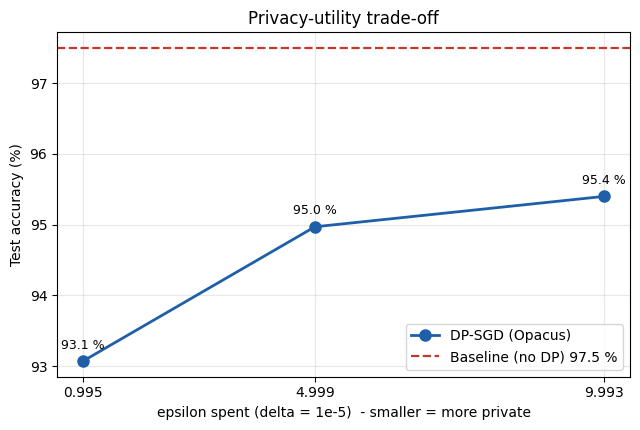

Plot saved : accuracy_vs_epsilon.png


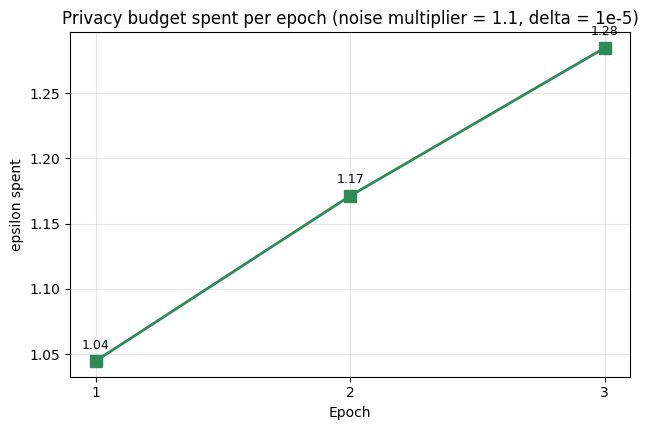

Plot saved : epsilon_vs_epoch.png


In [7]:
pts = sorted(dp_rows, key=lambda r: r["eps_spent"])
xs = [r["eps_spent"] for r in pts]
ys = [100 * r["test_acc"] for r in pts]

# ---- (a) privacy-utility curve ----
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.plot(xs, ys, "o-", color="#1f5fa8", lw=2, ms=8, label="DP-SGD (Opacus)")
ax.axhline(100 * base_acc, color="#c0392b", ls="--", lw=1.6, label=f"Baseline (no DP) {100 * base_acc:.1f} %")
for x, y_ in zip(xs, ys):
    ax.annotate(f"{y_:.1f} %", (x, y_), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xlabel("epsilon spent (delta = 1e-5)  - smaller = more private")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Privacy-utility trade-off")
ax.set_xticks(xs)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")

# ---- (b) epsilon vs epoch ----
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ep_axis = list(range(1, len(eps_per_epoch) + 1))
ax.plot(ep_axis, eps_per_epoch, "s-", color="#2e8b57", lw=2, ms=8)
for x, y_ in zip(ep_axis, eps_per_epoch):
    ax.annotate(f"{y_:.2f}", (x, y_), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xlabel("Epoch")
ax.set_ylabel("epsilon spent")
ax.set_title(f"Privacy budget spent per epoch (noise multiplier = {FIXED_SIGMA}, delta = 1e-5)")
ax.set_xticks(ep_axis)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("epsilon_vs_epoch.png", dpi=150)
plt.show()
print("Plot saved : epsilon_vs_epoch.png")

In [8]:
TOL_PP = 5.0                                              # acceptable accuracy loss (percentage points)

table = pd.DataFrame(
    [dict(Model="Baseline (no DP)", Target_eps="-", Eps_spent="-", Noise_sigma="-",
          Test_acc_pct=round(100 * base_acc, 1), Acc_change_pct="0.0")] +
    [dict(Model=f"DP-SGD eps={r['target_eps']:.0f}", Target_eps=r["target_eps"], Eps_spent=round(r["eps_spent"], 2),
          Noise_sigma=round(r["sigma"], 3), Test_acc_pct=round(100 * r["test_acc"], 1),
          Acc_change_pct=f"{100 * (r['test_acc'] - base_acc):+.1f}") for r in dp_rows])
print(table.to_string(index=False))
table.to_csv("results_summary.csv", index=False)

eligible = [r for r in dp_rows if 100 * (base_acc - r["test_acc"]) <= TOL_PP]
rec = min(eligible, key=lambda r: r["target_eps"]) if eligible else max(dp_rows, key=lambda r: r["target_eps"])
rec_cost = 100 * (rec["test_acc"] - base_acc)
REC_EPS = rec["target_eps"]
print(f"\nRecommended eps : {REC_EPS:.0f}  (only {rec_cost:+.1f} % accuracy, "
      f"{'strongest privacy among the options within the ' + str(TOL_PP) + ' % tolerance' if eligible else 'no option within tolerance - largest eps chosen'})")
print("Saved: results_summary.csv")

           Model Target_eps Eps_spent Noise_sigma  Test_acc_pct Acc_change_pct
Baseline (no DP)          -         -           -          97.5            0.0
   DP-SGD eps=10       10.0      9.99       0.521          95.4           -2.1
    DP-SGD eps=5        5.0       5.0       0.662          95.0           -2.5
    DP-SGD eps=1        1.0      0.99       1.235          93.1           -4.4

Recommended eps : 1  (only -4.4 % accuracy, strongest privacy among the options within the 5.0 % tolerance)
Saved: results_summary.csv
